# Evaluación 2 - Introducción a la Ciencia de Datos Espaciales 2026-2


Diego Eduardo Monja Zagaceta 20242642

# Preprocesamiento de la data entregada

In [1]:
#Instalamos las librerías necesarias
!pip install osmnx mapclassify

Lectura de datos

In [2]:
import geopandas as gpd

datos = "https://github.com/DiegoMonja/ICDE_EVALUACION_2/raw/refs/heads/main/2020_Census_Tracts_Seattle_8661193084158732132.zip"
seattle = gpd.read_file(datos)
seattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


Se disuelven los límites censales para obtener solo el límite de Seattle

In [3]:
seattle_dissolved = seattle.dissolve()
seattle_dissolved = seattle_dissolved[['geometry']]
seattle_dissolved

,geometry
0,"MULTIPOLYGON (((1260535.89 188253.83, 1260523...."


Elegimos la proyección adecuada en metros

In [4]:
seattle_dissolved = seattle_dissolved.to_crs(epsg=26910)
seattle_dissolved.crs

<Projected CRS: EPSG:26910>
Name: NAD83 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 126°W and 120°W - onshore and offshore. Canada - British Columbia; Northwest Territories; Yukon. United States (USA) - California; Oregon; Washington.
- bounds: (-126.0, 30.54, -119.99, 81.8)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

Obtenemos las estaciones de gasolina de Seattle

In [6]:
import osmnx as ox

estaciones = ox.features_from_place(
    "Seattle, Washington, USA",
    tags={'amenity': 'fuel'}
)
estaciones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

Observemos que existe un multi-index en los datos

In [7]:
estaciones.head()

geometry amenity     brand  \
element id                                                          
node    457773031   POINT (-122.39997 47.63939)    fuel   Chevron   
        631386821    POINT (-122.3203 47.62518)    fuel        76   
        771801423   POINT (-122.35525 47.73205)    fuel   Chevron   
        1197964284  POINT (-122.32958 47.58001)    fuel     Shell   
        1489962206  POINT (-122.32805 47.66483)    fuel  7-Eleven   

                   brand:wikidata              name addr:city  \
element id                                                      
node    457773031         Q319642  Magnolia Chevron       NaN   
        631386821        Q1658320                76   Seattle   
        771801423         Q319642           Chevron       NaN   
        1197964284     Q110716465             Shell       NaN   
        1489962206        Q259340          7-Eleven       NaN   

                   addr:housenumber addr:postcode      addr:street  \
element id                                                           
node    457773031               NaN           NaN              NaN   
        631386821               915         98102  East Roy Street   
        771801423               NaN           NaN              NaN   
        1197964284              NaN           NaN              NaN   
        1489962206              NaN           NaN              NaN   

                    check_date  ... start_date fuel:e85 maxheight  \
element id                      ...                                 
node    457773031          NaN  ...        NaN      NaN       NaN   
        631386821   2024-08-13  ...        NaN      NaN       NaN   
        771801423          NaN  ...        NaN      NaN       NaN   
        1197964284         NaN  ...        NaN      NaN       NaN   
        1489962206  2026-02-18  ...        NaN      NaN       NaN   

                   contact:facebook contact:instagram contact:phone  \
element id                                                            
node    457773031               NaN               NaN           NaN   
        631386821               NaN               NaN           NaN   
        771801423               NaN               NaN           NaN   
        1197964284              NaN               NaN           NaN   
        1489962206              NaN               NaN           NaN   

                   contact:twitter contact:youtube landuse mapwithai:source  
element id                                                                   
node    457773031              NaN             NaN     NaN              NaN  
        631386821              NaN             NaN     NaN              NaN  
        771801423              NaN             NaN     NaN              NaN  
        1197964284             NaN             NaN     NaN              NaN  
        1489962206             NaN             NaN     NaN              NaN  

[5 rows x 73 columns]

Procesamos las estaciones de gasolina

In [8]:
#Convierte el índice actual de estaciones en una columna, conservando los datos originales.
estaciones.reset_index(drop=False,inplace=True)

#Crea una copia que conserva únicamente las columnas del tipo de elemento, nombre y geometría de las estaciones.
seattle_estaciones=estaciones[['element','name','geometry']].copy()

#Reemplaza los nombres faltantes por "Unknown".
seattle_estaciones.fillna({'name':'Unknown'},inplace=True)

#Crea un identificador único para cada estación combinando su índice y su nombre.
seattle_estaciones['newname']=seattle_estaciones.index.astype(str)+"_"+seattle_estaciones.name

#Establece la columna newname como índice del GeoDataFrame.
seattle_estaciones.set_index('newname',inplace=True)

#Elimina la columna name, ya que el nombre original está incorporado en el nuevo índice.
seattle_estaciones.drop(columns=['name'],inplace=True)

#Transforma las geometrías al sistema de coordenadas EPSG:26910, que trabaja en metros y permite realizar análisis de distancias.
seattle_estaciones = seattle_estaciones.to_crs(epsg=26910)

seattle_estaciones

,element,geometry
newname,,
0_Magnolia Chevron,node,POINT (545070.577 5276395.041)
1_76,node,POINT (551068.412 5274865.552)
2_Chevron,node,POINT (548343.649 5286720.849)
3_Shell,node,POINT (550414.847 5269839.108)
4_7-Eleven,node,POINT (550448.153 5279266.856)
...,...,...
123_Gasco & South Seattle Market,way,"POLYGON ((546946.154 5265897.075, 546938.067 5..."
124_Shree's,way,"POLYGON ((549975.242 5264520.566, 549975.108 5..."
125_7-Eleven,way,"POLYGON ((555251.845 5281157.254, 555243.814 5..."


Observemos que hay más de un tipo de geometría en los datos

In [9]:
import pandas as pd
pd.crosstab(seattle_estaciones.element,seattle_estaciones.geometry.geom_type, margins=True)

col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


Repetimos el procedimiento para los centros educativos

In [10]:
centros_educativos = ox.features_from_place(
    "Seattle, Washington, USA",
    tags={'amenity': 'school'}
)
centros_educativos.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

In [11]:
centros_educativos.reset_index(drop=False,inplace=True)
seattle_centros_educativos=centros_educativos[['element','name','geometry']].copy()
seattle_centros_educativos.fillna({'name':'Unknown'},inplace=True)
seattle_centros_educativos['newname']=seattle_centros_educativos.index.astype(str)+"_"+seattle_centros_educativos.name
seattle_centros_educativos.set_index('newname',inplace=True)
seattle_centros_educativos.drop(columns=['name'],inplace=True)
seattle_centros_educativos = seattle_centros_educativos.to_crs(epsg=26910)

seattle_centros_educativos

,element,geometry
newname,,
0_Mapleleaf School,node,POINT (552925.436 5283350.335)
1_Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2_Epic Life Academy,node,POINT (549394.116 5283758.769)
3_Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4_Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)
...,...,...
212_Cascade Parent Partnership Program,way,"POLYGON ((548098.472 5277244.551, 548100.399 5..."
213_Roxhill Elementary School,way,"POLYGON ((547431.178 5262897.807, 547431.361 5..."
214_Downtown School,way,"POLYGON ((548578.229 5274295.401, 548578.413 5..."


In [12]:
pd.crosstab(seattle_centros_educativos.element, seattle_centros_educativos.geometry.geom_type, margins=True)

col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


Presentación de las ubicaciones de las estaciones de gasolina y los centros educativos

<Axes: title={'center': 'Ubicación de las estaciones de gasolina y centros educativos en Seattle, EE. UU.'}, xlabel='Easting [metre]', ylabel='Northing [metre]'>

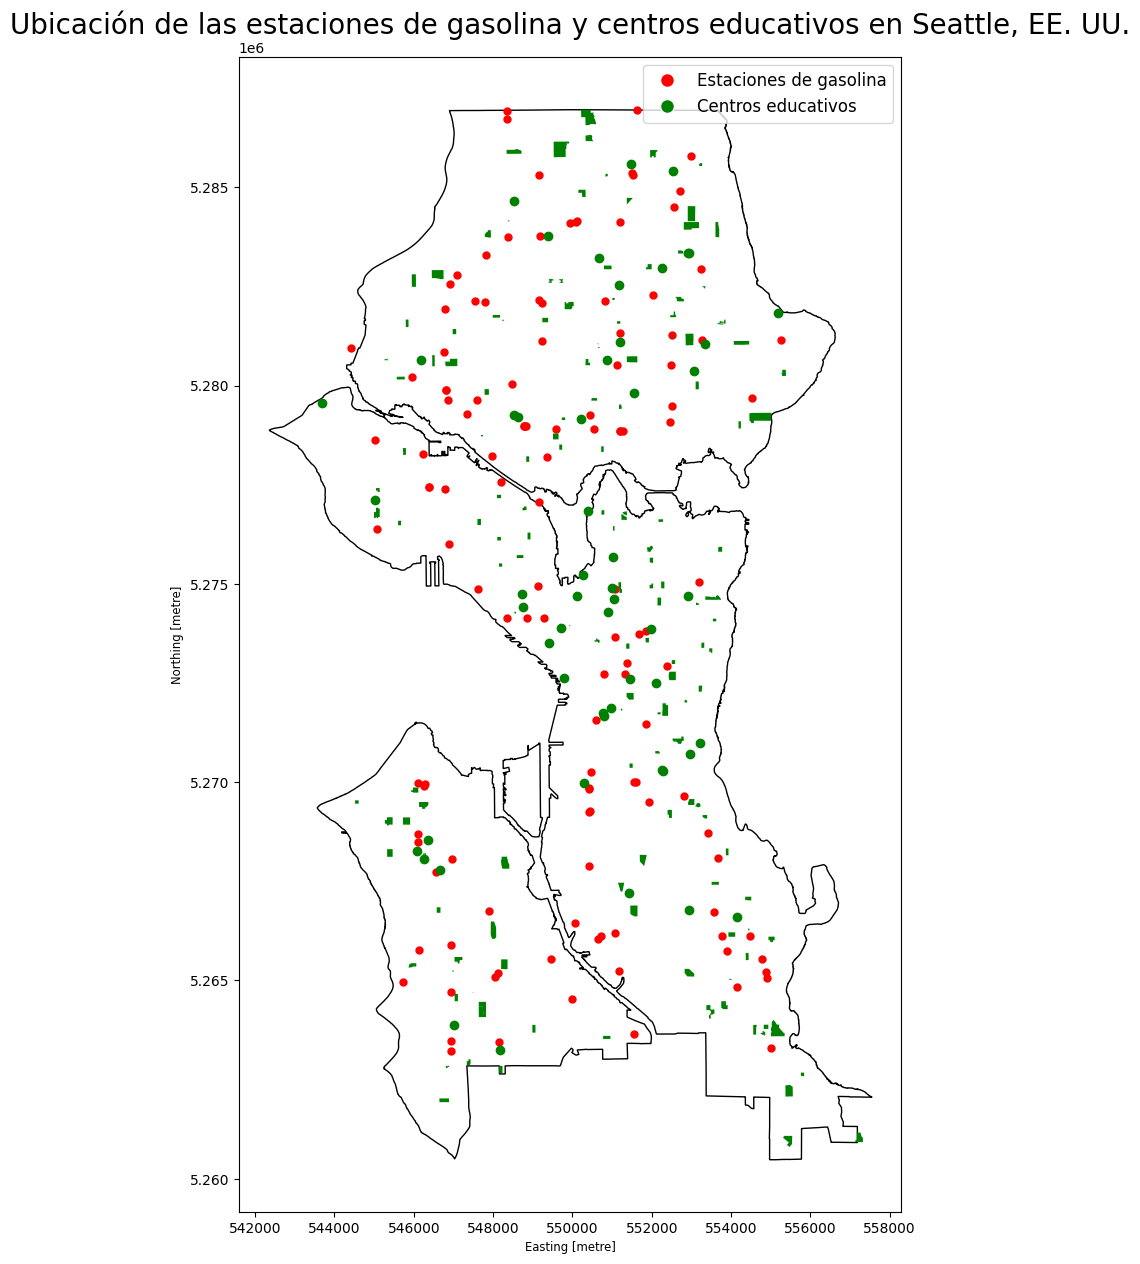

In [73]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

base=seattle_dissolved.plot(color='white', edgecolor='black', figsize=(15, 15))
base.set_title(
    'Ubicación de las estaciones de gasolina y centros educativos en Seattle, EE. UU.',
    fontsize=20
)

leyenda = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='red', markersize=10,
           label='Estaciones de gasolina'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='green', markersize=10,
           label='Centros educativos')
]

base.legend(handles=leyenda, loc='upper right', fontsize=12)

# Calculamos los centroides de todas las estaciones para representarlas como puntos visibles.
centros_estaciones = seattle_estaciones.geometry.centroid

# Graficamos las estaciones en color negro y con un tamaño mayor para facilitar su visualización.
base.scatter(
    centros_estaciones.x,
    centros_estaciones.y,
    color='red',
    s=25,
)
seattle_centros_educativos.plot(ax=base,color='green')

# 2. Procesamiento de la data

Exploración de las distancias entre estaciones de gasolina y centros educativos

In [14]:
matriz_estaciones_estaciones = seattle_estaciones.geometry.apply\
 (lambda estaciones: seattle_estaciones.geometry.distance(estaciones))
matriz_estaciones_estaciones


newname,0_Magnolia Chevron,1_76,2_Chevron,3_Shell,4_7-Eleven,5_7-Eleven,6_Morrison's North Star Marine,7_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel,9_76,...,118_Chevron,119_76,120_Chevron,121_Safeway Fuel Station,122_Shell,123_Gasco & South Seattle Market,124_Shree's,125_7-Eleven,126_Unknown,127_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,0.000000,6189.778099,10832.142978,8458.219249,6096.362935,3911.871820,4154.629544,4607.185893,3684.919842,6799.259673,...,11032.720301,8059.083730,8471.490011,11342.071122,8388.488702,10650.766388,12839.472695,11229.479609,9704.676294,10259.885224
1_76,6189.778099,0.000000,12164.390410,5068.756372,4444.794018,7396.837510,2913.822486,9025.058016,5776.876534,2146.281615,...,10502.171854,9283.591945,5828.349523,6582.987118,3490.937461,9859.853435,10391.001557,7544.714281,5423.572544,5486.468930
2_Chevron,10832.142978,12164.390410,0.000000,17008.322965,7745.382606,6939.794167,9680.781667,6982.575734,7498.129000,14199.195661,...,3434.731016,2961.691541,7436.375075,18706.121900,15655.292108,20857.745519,22251.515513,8863.786937,17578.604974,17632.751402
3_Shell,8458.219249,5068.756372,17008.322965,0.000000,9427.806838,11287.548358,7342.660400,12635.016000,9933.327451,2922.512744,...,15557.714940,14059.287367,10879.733945,3206.070889,2163.657924,5243.026228,5325.665547,12298.163104,1528.265114,2402.851126
4_7-Eleven,6096.362935,4444.794018,7745.382606,9427.806838,0.000000,4594.203464,2537.458079,6272.831613,3095.924539,6540.437675,...,6182.494529,4939.340577,2378.849213,10960.740771,7927.629559,13808.912707,14744.043923,5152.034055,9868.081904,9889.821437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,10650.766388,9859.853435,20857.745519,5243.026228,13808.912707,14330.734414,11384.887382,15256.296547,13384.622284,7840.707251,...,19975.906239,17895.800659,15622.732075,7048.807065,7406.644471,0.000000,3320.967459,17353.381510,6121.528764,6950.536820
124_Shree's,12839.472695,10391.001557,22251.515513,5325.665547,14744.043923,16185.514303,12571.965336,17343.197545,14990.551645,8245.361423,...,20883.253836,19286.809328,16183.027772,5393.694936,7165.874001,3320.967459,0.000000,17427.534449,5304.377123,5824.618469
125_7-Eleven,11229.479609,7544.714281,8863.786937,12298.163104,5152.034055,9340.534273,7314.479491,10839.148958,8108.038042,9514.437711,...,5617.194131,7342.966295,2828.590101,12564.668105,10253.850567,17353.381510,17427.534449,0.000000,12100.385190,11735.314154


In [15]:
matriz_estaciones_centros_edu = seattle_estaciones.geometry.apply\
 (lambda estaciones: seattle_centros_educativos.geometry.distance(estaciones))

matriz_estaciones_centros_edu

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,10491.659688,7199.084975,8539.173303,8956.657111,8932.523151,13341.958719,13507.709663,9506.260725,4487.653030,5324.737909,...,13761.296382,9053.687052,7195.602311,14410.390399,12230.115714,3124.787461,13580.295215,4054.694024,10282.565861,10565.424327
1_76,8685.624613,5789.863861,9049.451299,10124.534305,5853.770242,8808.620825,11975.722628,6599.617370,5074.222149,880.126226,...,9194.797832,6402.592462,6089.745057,10238.137431,10878.978200,3673.708903,12398.535914,2554.619356,8612.096410,6727.699624
2_Chevron,5687.981663,6575.805111,3142.833012,2065.133147,7921.183151,20929.652730,23474.696332,7563.706626,7465.701803,11654.725826,...,21301.486962,7045.990100,6198.145060,22392.998311,4983.299678,9477.043229,23725.977819,12427.156563,5446.866035,18854.337587
3_Shell,13742.500324,10822.941478,13957.036131,14944.971496,10856.827909,4930.152593,6965.257592,11596.129786,9605.655198,5388.607746,...,5347.980500,11437.825204,11106.714608,5956.588399,15939.807496,7649.546886,7450.088356,4780.314108,13675.664902,2107.909975
4_7-Eleven,4776.163021,1449.933898,4613.922112,5731.776499,2844.708492,13184.453100,16181.746778,3413.989799,1921.307178,4045.349103,...,13557.409322,2975.949318,1688.226327,14650.612357,6843.922072,3022.474841,16531.995201,5311.494858,4626.744314,11169.644124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,18437.654830,15257.637660,18016.092365,18818.447390,15701.177153,7223.804112,2917.573907,16447.522259,13440.851728,9890.137026,...,7489.956010,16219.730566,15482.629187,7043.580298,20596.596876,11308.744575,2917.011727,8493.599402,18333.769195,5192.808772
124_Shree's,19046.714482,16146.376840,19238.321146,20186.490665,16131.338043,4633.509651,2212.511637,16863.752907,14799.205507,10699.306284,...,4762.577365,16729.265591,16426.505984,3973.425033,21246.496324,12755.913237,2957.170911,9823.178035,18986.753055,3812.301432
125_7-Eleven,3191.366019,4396.077208,6402.128582,7587.141782,2308.936140,14581.418422,19250.984757,1890.496999,6978.426106,7738.111508,...,14859.036606,2191.162884,4562.774267,16156.189878,4800.640849,8052.316222,19748.085148,9560.847169,3273.765496,13416.903822


Ubicación de las estaciones que se encuentren a menos de 200 metros de un centro educativo

In [16]:
distancia_minima = 200
#Creamos una zona segura para los colegios
seattle_centros_edu_buffered = seattle_centros_educativos.buffer(distancia_minima)
seattle_centros_edu_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


In [17]:
type(seattle_centros_edu_buffered)

geopandas.geoseries.GeoSeries

In [18]:
#Pasamos de GS a GDF
seguro_seattle_centros_edu = gpd.GeoDataFrame(geometry=seattle_centros_edu_buffered)
seguro_seattle_centros_edu

,geometry
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


Estandarizamos las geometrias de las estaciones de gas

In [19]:
seattle_estaciones.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


In [20]:
seattle_estaciones_allPoly = seattle_estaciones.copy()
seattle_estaciones_allPoly['geometry'] = [
    estaciones.buffer(10) if estaciones.geom_type == 'Point' else estaciones
    for estaciones in seattle_estaciones.geometry
]

In [21]:
#revisamos
seattle_estaciones_allPoly.geometry.geom_type.value_counts()


,count
Polygon,128


In [22]:
#Hallamos las estaciones de gasolina que no cumplen
estaciones_reubicacion = seattle_estaciones_allPoly.sjoin(seguro_seattle_centros_edu, how='inner', predicate='intersects')
estaciones_reubicacion

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.807, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School


In [23]:
#Buscamos duplicados, pues algunas estaciones pueden estar cerca a más de un centro educativo
duplicados = estaciones_reubicacion.index.duplicated(keep=False)
estaciones_reubicacion[duplicados]

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",187_Nova High School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",198_Seattle World School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",116_Morningside Academy
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",51_The Hatch School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",198_Seattle World School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",116_Morningside Academy


Obtenemos la lista de estaciones a reubicar al eliminar los duplicados

In [24]:
estaciones_reubicacion = estaciones_reubicacion.reset_index(drop=False).\
drop_duplicates(subset='newname_left').\
set_index('newname_left')

In [25]:
estaciones_reubicacion.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 26 entries, 1_76 to 127_Arco
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   element        26 non-null     object  
 1   geometry       26 non-null     geometry
 2   newname_right  26 non-null     object  
dtypes: geometry(1), object(2)
memory usage: 832.0+ bytes


Ahora observemos las estaciones ha reubicar

In [26]:
base=seguro_seattle_centros_edu.sjoin(estaciones_reubicacion, how='inner', predicate='intersects').explore(color='yellow', tiles='cartodbpositron')
estaciones_reubicacion.explore(m=base, color='red')

/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


En caso no se observe la gráfica anterior

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

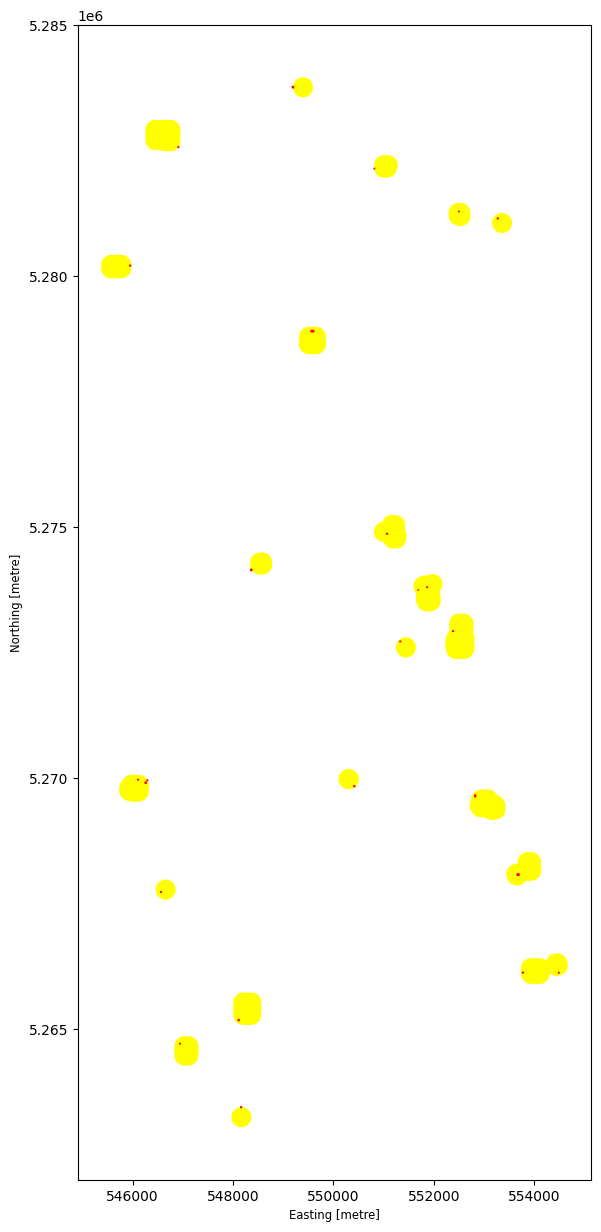

In [27]:
base=seguro_seattle_centros_edu.sjoin(estaciones_reubicacion, how='inner', predicate='intersects').plot(color='yellow', figsize=(15,15))
estaciones_reubicacion.plot(ax=base, facecolor='red', edgecolor='red')

# 3. Reubicación de las estaciones de gasolina encontradas

En este caso, como se puede colocar una estación de gas en cualquier lugar, se considerará su reubicación en las carreteras de la región

In [28]:
place = "Seattle, Washington, USA"
#Descargamos las calles de Seattle
G = ox.graph_from_place(place, network_type="drive")
#Convertimos los datos (graph edges) a un GeoDataFrame
calles = ox.graph_to_gdfs(G, nodes=False, edges=True)

calles.shape

(50301, 15)

In [29]:
calles = calles.to_crs(epsg=26910)

In [30]:
calles.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


Nos enfocaremos en la columna "highway"

In [31]:
calles.highway.value_counts().index

Index([                    'residential',                        'tertiary',
                             'secondary',                         'primary',
                          'unclassified',                   'motorway_link',
                                 'trunk',                        'motorway',
                          'primary_link',                  'secondary_link',
                         'tertiary_link',                   'living_street',
         ['residential', 'unclassified'],                      'trunk_link',
                                'busway',         ['secondary', 'tertiary'],
        ['living_street', 'residential'],          ['primary', 'secondary'],
           ['motorway', 'motorway_link'],          ['secondary', 'primary'],
             ['residential', 'tertiary'],      ['unclassified', 'tertiary'],
              ['trunk_link', 'tertiary'],      ['tertiary', 'unclassified'],
       ['secondary_link', 'residential'],     ['residential', 'trunk_link'],

In [32]:
TIPOS_CALLES_ESTACIONES = [
    'motorway', #Vías de acceso limitado de alta velocidad
    'primary', #Carreteras nacionales principales
    'trunk', #Carreteras regionales importantes
    'motorway_link', #Rampas de entrada/salida de autopistas
    'primary_link', #Conectores de carreteras importantes
    ['motorway', 'trunk'],
    ['primary', 'motorway_link'],
    ['primary', 'primary_link']
]

carreteras_adecuadas = calles[calles.highway.isin(TIPOS_CALLES_ESTACIONES)]

carreteras_adecuadas.shape

(3691, 15)

In [33]:
#Reproyectamos
carreteras_adecuadas = carreteras_adecuadas.to_crs(epsg=26910)

Las reubicaciones deben considerar lo siguiente:


*   Deben estar lo suficientemente lejos de los centros de estudio. Deben estar lejos del GDF seguro_seattle_centros_edu
*   Deben estar lo suficientemente lejos de otras estaciones de gas. Se debe dar otro buffer a seattle_estaciones_allPoly



In [34]:
DistanciaCompetente = 100
#Apartir de la matriz estación-estación
seattle_estaciones_allPoly_buffered=seattle_estaciones_allPoly.buffer(DistanciaCompetente)

In [35]:
#Revisamos si tenemos un GDF
type(seattle_estaciones_allPoly_buffered)

geopandas.geoseries.GeoSeries

In [36]:
#Pasamos a GDF
seguro_seattle_estaciones_allPoly = gpd.GeoDataFrame(geometry=seattle_estaciones_allPoly_buffered)

In [37]:
areas_seguras_disueltas = seguro_seattle_estaciones_allPoly.overlay(seguro_seattle_centros_edu,how='union',keep_geom_type=False).dissolve()
areas_seguras = gpd.GeoDataFrame(geometry=areas_seguras_disueltas.geometry)

Entonces filtramos las rutas usando overlay

In [38]:
buenas_rutas_paraGas_dissolved = carreteras_adecuadas.overlay(areas_seguras,how='difference',keep_geom_type=False).dissolve()
buenas_rutas_paraGas = gpd.GeoDataFrame(geometry=buenas_rutas_paraGas_dissolved.geometry)
buenas_rutas_paraGas

,geometry
0,"MULTILINESTRING ((551005.064 5276789.854, 5510..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

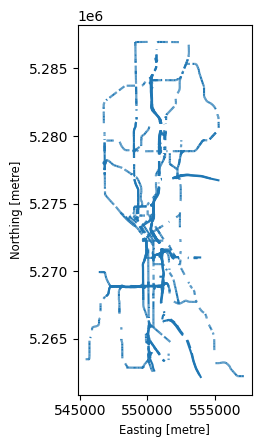

In [39]:
buenas_rutas_paraGas.plot()

In [40]:
localizaciones_potenciales = buenas_rutas_paraGas.copy()
nuevosPoligonos = []
puntosComputed = 1
intentos = 1

while puntosComputed <= len(estaciones_reubicacion):
    # Generamos dos puntos y seleccionamos uno
    puntos_muestreados = localizaciones_potenciales.sample_points(2)
    punto = puntos_muestreados.iloc[0].geoms[0] #.iloc selecciona la fila y .geoms selecciona el primer punto de la geometría de esa fila
    # Creamos un búfer de 100 metros alrededor del punto
    estacionCandidata = gpd.GeoDataFrame(
        geometry=[punto.buffer(100)],
        crs=localizaciones_potenciales.crs
    )
    # Comprobamos que la ubicación no interseque las áreas seguras
    if estacionCandidata.overlay(
        areas_seguras,
        how='intersection',
        keep_geom_type=False
    ).empty:
        nuevosPoligonos.append(estacionCandidata)
        puntosComputed += 1
        # Retiramos esa zona de las carreteras disponibles
        localizaciones_potenciales = localizaciones_potenciales.overlay(
            estacionCandidata,
            how='difference',
            keep_geom_type=False
        )
    if intentos > len(estaciones_reubicacion) * 10:
        break
    intentos += 1
#Vemos los resultados
intentos, len(nuevosPoligonos)

(29, 26)

In [41]:
nuevosPoligonos

[                                            geometry
 0  POLYGON ((550522.442 5271239.397, 550521.961 5...,
                                             geometry
 0  POLYGON ((550838.559 5265587.703, 550838.078 5...,
                                             geometry
 0  POLYGON ((550580.736 5265808.437, 550580.254 5...,
                                             geometry
 0  POLYGON ((550431.047 5274924.64, 550430.566 52...,
                                             geometry
 0  POLYGON ((554290.321 5283112.9, 554289.839 528...,
                                             geometry
 0  POLYGON ((548032.214 5267087.89, 548031.732 52...,
                                             geometry
 0  POLYGON ((547320.045 5278093.013, 547319.563 5...,
                                             geometry
 0  POLYGON ((550692.678 5285699.583, 550692.196 5...,
                                             geometry
 0  POLYGON ((550975.079 5277549.446, 550974.597 5...,
                   

In [42]:
#Guardamos los resultados
NuevasUbicaciones_buffered_gdf = pd.concat(nuevosPoligonos)
NuevasUbicaciones_gdf=gpd.GeoDataFrame(geometry=NuevasUbicaciones_buffered_gdf.centroid)
NuevasUbicaciones_gdf

,geometry
0,POINT (550422.442 5271239.397)
0,POINT (550738.559 5265587.703)
0,POINT (550480.736 5265808.437)
0,POINT (550331.047 5274924.64)
0,POINT (554190.321 5283112.9)
0,POINT (547932.214 5267087.89)
0,POINT (547220.045 5278093.013)
0,POINT (550592.678 5285699.583)
0,POINT (550875.079 5277549.446)
0,POINT (549627.127 5272992.671)


# 4. Gráfica de los resultados finales

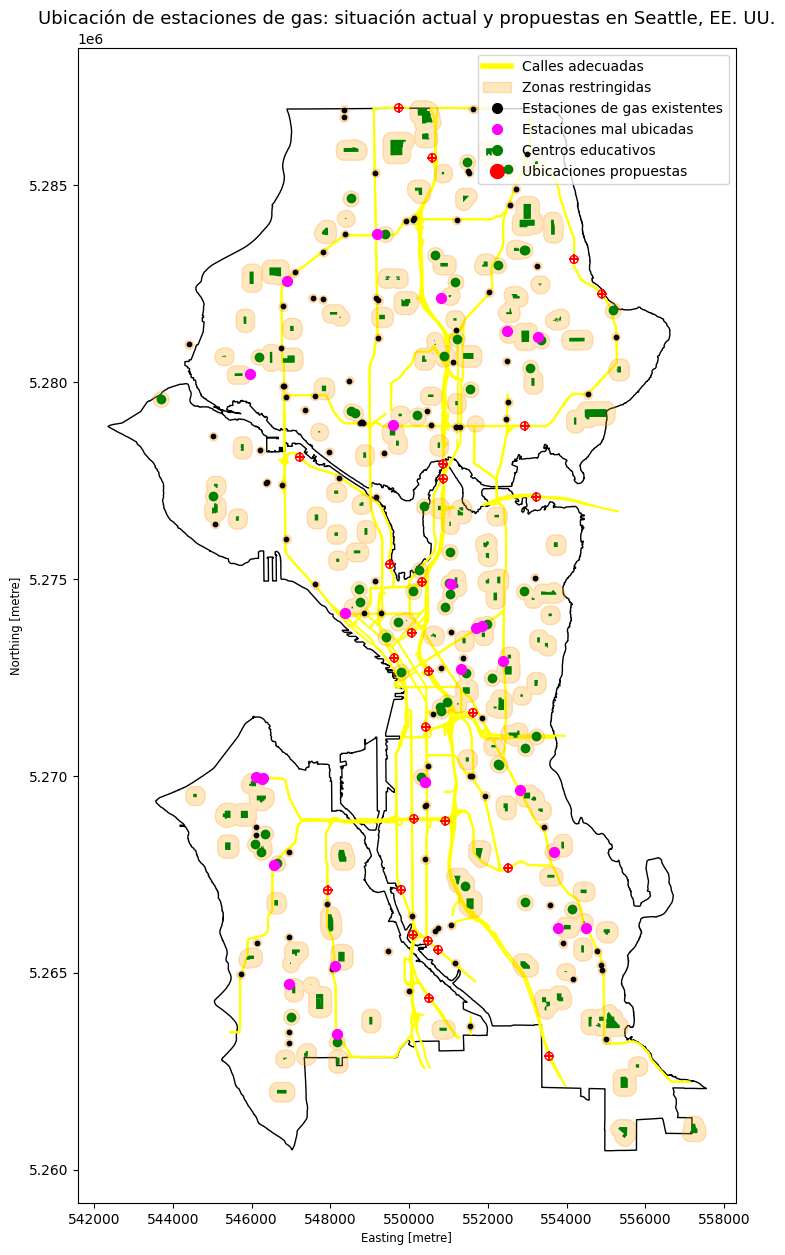

In [70]:
#Calles originales adecuadas
base=seattle_dissolved.plot(color='white', edgecolor='black', figsize=(15,15), zorder=1)
carreteras_adecuadas.plot(ax=base, color='yellow', figsize=(15,15), zorder=2)

base.set_title(
    'Ubicación de estaciones de gas: situación actual y propuestas en Seattle, EE. UU.',
    fontsize=13
)

# Zonas restringidas
areas_seguras.plot(ax=base, color='orange', edgecolor='darkorange', alpha=0.25, zorder=3)

#Nuevas reubicaciones de las estaciones mal ubicadas están de color rojo
NuevasUbicaciones_buffered_gdf.plot(ax=base, edgecolor='red', marker="+", facecolor='none', zorder=4)
NuevasUbicaciones_gdf.plot(ax=base, color='red', marker="+", markersize=50, zorder=5)

#Todas las estaciones y colegios, las estaciones antiguas y bien ubicadas tienen color negro
seattle_centros_educativos.plot(ax=base, color='green', zorder=6)

# Calculamos los centroides de todas las estaciones para representarlas como puntos visibles.
centros_estaciones = seattle_estaciones.geometry.centroid

# Graficamos las estaciones en color negro y con un tamaño mayor para facilitar su visualización.
base.scatter(
    centros_estaciones.x,
    centros_estaciones.y,
    color='black',
    s=10,
    zorder=7
)

# Como las estaciones mal ubicadas no se ven, seleccionamos las estaciones mal ubicadas mediante el recorte espacial con las zonas identificadas para reubicación.
estaciones_mal_ubicadas = seattle_estaciones.clip(
    estaciones_reubicacion
)

#Calculamos los centroides de las estaciones para representarlas como puntos y facilitar su visualización.
centros_mal_ubicadas = estaciones_mal_ubicadas.geometry.centroid

#Graficamos los centroides en color magenta y con un tamaño visible para distinguir las estaciones mal ubicadas.
base.scatter(
    centros_mal_ubicadas.x,
    centros_mal_ubicadas.y,
    color='magenta',
    s=50,
    zorder=8
)

# Leyenda personalizada
leyenda = [
    Line2D([0], [0], color='yellow', linewidth=4,
           label='Calles adecuadas'),
    Patch(facecolor='orange', edgecolor='darkorange', alpha=0.25,
          label='Zonas restringidas'),
    Line2D([0], [0], marker='o', color='black', linestyle='None',
           markersize=7, label='Estaciones de gas existentes'),
    Line2D([0], [0], marker='o', color='magenta', linestyle='None',
           markersize=7, label='Estaciones mal ubicadas'),
    Line2D([0], [0], marker='o', color='green', linestyle='None',
           markersize=7, label='Centros educativos'),
    Line2D([0], [0], marker='o', color='red', linestyle='None',
           markersize=10, label='Ubicaciones propuestas')
]

base.legend(handles=leyenda, loc='upper right', fontsize=10)

# 5. Codificación inversa

Hallamos las ubicaciones exactactas de las reubicaciones de las estaciones de gasolina que no cumplen con el mínimo de 200 m

In [44]:
from geopy.geocoders import Nominatim
import time

geolocator = Nominatim(user_agent="seattle_gas_stations")

def get_address(point):
  #Las nuevas coordenadas están en grados (Lon, Lat)
  lon = point.x
  lat = point.y
  location = geolocator.reverse((lat,lon), exactly_one=True, timeout=10)
  time.sleep(1)

  if location:
    return location.address
  else:
    return None #no encontrado

In [45]:
NuevasUbicaciones_4326 = NuevasUbicaciones_gdf.to_crs(epsg=4326)
NuevasUbicaciones_gdf['address'] = NuevasUbicaciones_4326.geometry.apply(get_address)
NuevasUbicaciones_gdf

,geometry,address
0,POINT (550422.442 5271239.397),"394, South Royal Brougham Way, Yesler Terrace,..."
0,POINT (550738.559 5265587.703),"6851, East Marginal Way South, Van Asselt, Geo..."
0,POINT (550480.736 5265808.437),"6701, East Marginal Way South, Van Asselt, Geo..."
0,POINT (550331.047 5274924.64),"1398, Valley Street, South Lake Union, Cascade..."
0,POINT (554190.321 5283112.9),"Treehouse Massage Therapy at Annie Firefly, 95..."
0,POINT (547932.214 5267087.89),"5072, Delridge Way Southwest, Delridge, Seattl..."
0,POINT (547220.045 5278093.013),"Northern Lights, 1017, West Nickerson Street, ..."
0,POINT (550592.678 5285699.583),"Northeast 130th Street, Haller Lake, Seattle, ..."
0,POINT (550875.079 5277549.446),"Ship Canal Bridge, Burke-Gilman Trail, West Ca..."
0,POINT (549627.127 5272992.671),"State Route 99 Tunnel, South Lake Union, Casca..."
